# The pollution-side test: did the industrial neighborhood change?

Third piece in this chain. `dc_ej_hosting_gap.ipynb` found data-center ZIPs score worse on
EJ burden, surviving a density control. `dc_ej_selection_vs_impact.ipynb` tested the
demographic half of that gap historically and found it's mostly selection (87% already
present in 2013). Simon's follow-up: get more EPA data and test the *pollution* half the
same way -- that piece explicitly flagged it as unable to go historical.

**What EPA data actually allows this, found by checking before building:** the pollution/
hazard half of `ej_score` (contamination, superfund, RCRA, air quality) has no historical
read available cheaply -- Superfund/RCRA sites don't expose listing dates through the API
fields the live pipeline pulls, and air-quality nonattainment history is a bigger lift than
scoped here. But EPA's Toxics Release Inventory (TRI) -- the same dataset the live
`contamination_score` already uses for current-snapshot proximity -- turns out to support a
`REPORTING_YEAR` filter through the same Envirofacts API `04_environment.py` already calls.
That allows a real before/after: distance to the nearest ACTIVELY REPORTING TRI facility, for
2013 vs. 2022, per ZCTA.

**What this can and cannot show, stated up front:** data centers themselves essentially never
show up in TRI -- it tracks chemical manufacturing/processing releases, not IT/cooling
infrastructure. So this cannot test whether a data center directly polluted. What it CAN test
is whether the *surrounding industrial neighborhood* near data-center ZIPs intensified
differently than elsewhere -- a real question (co-located industrial development, land/power
economics that draw both), just not the same as "the data center caused it." Two live
alternative explanations for anything found here: (1) both data centers and new industrial
facilities are independently drawn to the same cheap-land/available-power/light-zoning areas,
or (2) reverse causality -- an area's rising industrial footprint could itself be one of the
things that makes it attractive for data-center siting. This test cannot distinguish those
from a genuine spillover effect.

**Two real data problems hit and fixed while building this, not glossed over:**
- **`TRI_REPORTING_FORM` has no working state filter.** Passing `STATE_ABBR/<abbr>` in the
  API path is silently ignored, not an error -- confirmed by requesting two different states
  and getting byte-identical rows back. Worked around by pulling the table nationally,
  filtered only by `REPORTING_YEAR` (~80-83K rows/year, paginated), then joining to a
  per-state `TRI_FACILITY` roster (whose state filter *does* work) by facility ID.
- **EPA's own facility geocoding is incomplete, and unevenly so between years.** ~20-25% of
  TRI facilities have no usable `pref_latitude`/`longitude` or DDMMSS fallback at all -- a
  real EPA data gap, not a parsing bug (checked directly against raw fields). Worse, the gap
  wasn't even across years: only 61.3% of 2022's active reporters resolved to real
  coordinates vs. 73.8% of 2013's, which would have mechanically shrunk 2022's candidate pool
  and biased its distances farther for a reason that had nothing to do with real change.
  Fixed with a ZIP-code-centroid fallback (every US ZIP's centroid is already on hand from
  merascope's national ZCTA table) for facilities EPA never geocoded -- closed the gap from
  12.5 points to 0.1 points between years.

In [1]:
from pathlib import Path

import numpy as np
import numpy.linalg as la
import pandas as pd
from scipy import stats

tri = pd.read_csv("data/tri_zcta_distance.csv", dtype={"zcta": str})
mt = pd.read_csv("../../merascope/notebooks/cache/model_table.csv", dtype={"zcta": str})
lab = pd.read_csv("../../merascope/data/datacenters/zcta_labels.csv", dtype={"zcta": str})
mt = mt.merge(lab, on="zcta", how="left")
for c in ["n_built", "has_dc"]:
    mt[c] = mt[c].fillna(0).astype(int)

d = mt[["zcta", "has_dc", "pop_exposure_score", "state"]].merge(tri, on="zcta", how="inner")
d["density_axis"] = 1 - d["pop_exposure_score"]
d = d.dropna(subset=["tri_dist_km_2013", "tri_dist_km_2022", "density_axis"]).copy()
d["delta"] = d["tri_dist_km_2022"] - d["tri_dist_km_2013"]  # positive = moved FARTHER (better)

print(f"{len(d)} ZCTAs, {int(d['has_dc'].sum())} hosting a confirmed built data center")
assert len(d) > 30000, "unexpectedly large join loss -- check the merge"

33252 ZCTAs, 1196 hosting a confirmed built data center


## Level comparison: was the industrial neighborhood already denser near hosting ZIPs?

In [2]:
host, non = d[d.has_dc == 1], d[d.has_dc == 0]

for year, col in [(2013, "tri_dist_km_2013"), (2022, "tri_dist_km_2022")]:
    _, p = stats.mannwhitneyu(host[col], non[col])
    print(f"{year}: hosting median={host[col].median():.2f} km (mean {host[col].mean():.2f})  "
          f"non-hosting median={non[col].median():.2f} km (mean {non[col].mean():.2f})  p={p:.1e}")

assert host["tri_dist_km_2013"].median() < non["tri_dist_km_2013"].median(), \
    "expected hosting ZIPs already closer to active industry in 2013"
print("\nSame direction as the demographic piece: hosting ZIPs were already embedded in a far")
print("denser industrial landscape a decade ago -- roughly 5x closer to the nearest active TRI")
print("facility than non-hosting ZIPs, in both years. Selection again, at the level.")

2013: hosting median=1.83 km (mean 4.72)  non-hosting median=9.57 km (mean 14.14)  p=5.8e-201
2022: hosting median=1.23 km (mean 3.91)  non-hosting median=9.63 km (mean 14.18)  p=1.1e-223

Same direction as the demographic piece: hosting ZIPs were already embedded in a far
denser industrial landscape a decade ago -- roughly 5x closer to the nearest active TRI
facility than non-hosting ZIPs, in both years. Selection again, at the level.


## Did it change differently? The actual treatment test

Unlike the demographic piece, this is not "how much of the level gap predates the boom" --
`tri_dist_km` levels reflect where industry already was and would be hard to compare as a
clean percentage-of-gap the way `demog_index` was. The real test here is the *change*:
did hosting ZIPs' distance to active industry shrink (get worse) more than non-hosting ZIPs',
controlling for density and where each ZIP started?

In [3]:
_, p_delta = stats.mannwhitneyu(host["delta"], non["delta"])
print(f"raw delta (2022 - 2013, +=farther/better): hosting mean={host['delta'].mean():+.3f} km  "
      f"non-hosting mean={non['delta'].mean():+.3f} km  (Mann-Whitney p={p_delta:.4f})")


def ols(y, X):
    X1 = np.column_stack([np.ones(len(X)), X])
    beta, *_ = la.lstsq(X1, y, rcond=None)
    resid = y - X1 @ beta
    dof = len(y) - X1.shape[1]
    sigma2 = (resid @ resid) / dof
    se = np.sqrt(np.diag(sigma2 * la.inv(X1.T @ X1)))
    return beta, beta / se


y = d["delta"].to_numpy()
has_dc = d["has_dc"].to_numpy().astype(float)
X = d[["density_axis", "tri_dist_km_2013"]].to_numpy().astype(float)
beta, t = ols(y, np.column_stack([has_dc, X]))
print(f"\ndelta ~ has_dc + density_axis + baseline tri_dist_km_2013:")
print(f"  has_dc coef      = {beta[1]:+.4f} km  (t={t[1]:.2f})")
print(f"  density_axis     = {beta[2]:+.4f}  (t={t[2]:.2f})")
print(f"  baseline (2013)  = {beta[3]:+.4f}  (t={t[3]:.2f})  -- mean reversion")

rng = np.random.RandomState(0)
N_PERM = 200
null = np.empty(N_PERM)
for i in range(N_PERM):
    shuf = rng.permutation(has_dc)
    b, _ = ols(y, np.column_stack([shuf, X]))
    null[i] = b[1]
p_perm = (np.sum(np.abs(null) >= abs(beta[1])) + 1) / (N_PERM + 1)
print(f"\n200-shuffle permutation null on the has_dc coefficient: mean={null.mean():+.4f}, "
      f"std={null.std():.4f}, p={p_perm:.4f}")

assert beta[1] < 0, "expected hosting ZIPs to have moved CLOSER (negative delta) net of controls"
assert p_perm < 0.05, "the widening doesn't clear a permutation null -- don't claim it as real"
print(f"\nReal, and NOT small the way the demographic residual was: hosting ZIPs' distance to the")
print(f"nearest active TRI facility shrank {abs(beta[1]):.2f} km more than density- and baseline-")
print(f"matched non-hosting ZIPs over 9 years. This is the more impact-consistent of the two")
print(f"pieces so far -- though still not proof the data center caused it (see the intro's two")
print(f"live alternative explanations).")

raw delta (2022 - 2013, +=farther/better): hosting mean=-0.811 km  non-hosting mean=+0.037 km  (Mann-Whitney p=0.0084)

delta ~ has_dc + density_axis + baseline tri_dist_km_2013:
  has_dc coef      = -1.2864 km  (t=-6.08)
  density_axis     = -1.2232  (t=-8.38)
  baseline (2013)  = -0.0827  (t=-35.30)  -- mean reversion

200-shuffle permutation null on the has_dc coefficient: mean=+0.0360, std=0.1940, p=0.0050

Real, and NOT small the way the demographic residual was: hosting ZIPs' distance to the
nearest active TRI facility shrank 1.29 km more than density- and baseline-
matched non-hosting ZIPs over 9 years. This is the more impact-consistent of the two
pieces so far -- though still not proof the data center caused it (see the intro's two
live alternative explanations).


In [4]:
# Matched comparison: same density-quintile-within-state design as the other two pieces.
d["density_q"] = d.groupby("state")["density_axis"].transform(
    lambda s: pd.qcut(s.rank(method="first"), 5, labels=False, duplicates="drop") + 1)


def summarize(g):
    return pd.Series({
        "n_host": int((g.has_dc == 1).sum()), "n_non": int((g.has_dc == 0).sum()),
        "delta_host": g.loc[g.has_dc == 1, "delta"].mean(),
        "delta_non": g.loc[g.has_dc == 0, "delta"].mean(),
    })


tab = d.groupby("density_q").apply(summarize)
tab["gap"] = tab["delta_host"] - tab["delta_non"]
print("within-state density quintile (1=least dense, 5=most dense), mean delta km "
      "(2022-2013, +=farther/better):")
print(tab.round(3))

assert (tab["gap"] < 0).all(), "hosting ZIPs should have shrunk more than non-hosting in EVERY quintile"
print(f"\nSame direction in all 5 quintiles -- not an artifact of one extreme bin. Magnitude varies "
      f"a lot (quintiles 1-2 have few hosting ZIPs, n={tab['n_host'][1]:.0f} and {tab['n_host'][2]:.0f}, "
      f"so those two gaps are noisier and shouldn't be read as precise -- quantified properly below).")

within-state density quintile (1=least dense, 5=most dense), mean delta km (2022-2013, +=farther/better):
           n_host   n_non  delta_host  delta_non    gap
density_q                                              
1            38.0  6632.0      -4.952      0.258 -5.211
2            59.0  6580.0      -5.312     -0.107 -5.205
3           143.0  6502.0      -0.547     -0.037 -0.509
4           306.0  6333.0      -0.776     -0.078 -0.697
5           650.0  6009.0      -0.235      0.150 -0.385

Same direction in all 5 quintiles -- not an artifact of one extreme bin. Magnitude varies a lot (quintiles 1-2 have few hosting ZIPs, n=38 and 59, so those two gaps are noisier and shouldn't be read as precise -- quantified properly below).


## Quantifying the shakiness: bootstrap CIs, then a continuous test

Simon's direct follow-up after seeing the quintile chart: quintiles 1-2 have only 38 and 59
hosting ZIPs -- how shaky is "shaky," and is the density-varying pattern itself real or just
small-n noise in the sparse bins? Two fixes, not one: bootstrap confidence intervals on each
quintile's gap (so the chart shows uncertainty instead of a caption caveat), and a continuous
regression with a `has_dc x density_axis` interaction term that uses all 1,196 hosting ZIPs at
once instead of splitting them into 5 uneven bins -- the interaction coefficient is the real
test of "does this effect actually vary with density," and it gets its own permutation test,
same discipline as every other coefficient in this series.

In [5]:
N_BOOT = 2000
ci_lo, ci_hi = [], []
for q in range(1, 6):
    g = d[d.density_q == q]
    host_vals = g.loc[g.has_dc == 1, "delta"].to_numpy()
    non_vals = g.loc[g.has_dc == 0, "delta"].to_numpy()
    boot = np.empty(N_BOOT)
    for i in range(N_BOOT):
        bh = rng.choice(host_vals, size=len(host_vals), replace=True)
        bn = rng.choice(non_vals, size=len(non_vals), replace=True)
        boot[i] = bh.mean() - bn.mean()
    lo, hi = np.percentile(boot, [2.5, 97.5])
    ci_lo.append(lo)
    ci_hi.append(hi)
tab["ci_lo"], tab["ci_hi"] = ci_lo, ci_hi
tab["ci_excludes_zero"] = (tab["ci_hi"] < 0) | (tab["ci_lo"] > 0)
print("bootstrap 95% CI per quintile (2000 resamples):")
print(tab[["n_host", "gap", "ci_lo", "ci_hi", "ci_excludes_zero"]].round(3))
print(f"\n{int(tab['ci_excludes_zero'].sum())}/5 quintiles individually clear a 95% CI -- "
      f"quintile 3 does not (its own CI crosses zero), quintile 1's barely does. Read the "
      f"pattern from the continuous test below, not from treating each bar as its own finding.")

bootstrap 95% CI per quintile (2000 resamples):
           n_host    gap   ci_lo  ci_hi  ci_excludes_zero
density_q                                                
1            38.0 -5.211 -11.217 -0.170              True
2            59.0 -5.205  -9.262 -1.822              True
3           143.0 -0.509  -1.554  0.504             False
4           306.0 -0.697  -1.236 -0.228              True
5           650.0 -0.385  -0.701 -0.110              True

4/5 quintiles individually clear a 95% CI -- quintile 3 does not (its own CI crosses zero), quintile 1's barely does. Read the pattern from the continuous test below, not from treating each bar as its own finding.


In [6]:
density = X[:, 0]  # density_axis column, same source X used for the earlier controlled regression
baseline_dist = X[:, 1]  # tri_dist_km_2013

interact = has_dc * density
X_int = np.column_stack([has_dc, density, interact, baseline_dist])
beta_int, t_int = ols(y, X_int)
print("delta ~ has_dc + density_axis + has_dc:density_axis + baseline:")
print(f"  has_dc          = {beta_int[1]:+.4f}  (t={t_int[1]:.2f})")
print(f"  density_axis    = {beta_int[2]:+.4f}  (t={t_int[2]:.2f})")
print(f"  has_dc:density  = {beta_int[3]:+.4f}  (t={t_int[3]:.2f})")
print(f"  baseline (2013) = {beta_int[4]:+.4f}  (t={t_int[4]:.2f})")

null_int = np.empty(N_PERM)
for i in range(N_PERM):
    shuf = rng.permutation(has_dc)
    Xp = np.column_stack([shuf, density, shuf * density, baseline_dist])
    b, _ = ols(y, Xp)
    null_int[i] = b[3]
p_perm_int = (np.sum(np.abs(null_int) >= abs(beta_int[3])) + 1) / (N_PERM + 1)
print(f"\n200-shuffle permutation null on the interaction term: mean={null_int.mean():+.4f}, "
      f"std={null_int.std():.4f}, p={p_perm_int:.4f}")

assert p_perm_int < 0.05, "interaction doesn't clear a permutation null -- the density-varying pattern isn't real, say so"
low_d, high_d = 0.1, 0.9
implied_low = beta_int[1] + beta_int[3] * low_d
implied_high = beta_int[1] + beta_int[3] * high_d
print(f"\nReal: the has_dc effect genuinely shrinks as density rises, not small-n noise in quintiles")
print(f"1-2. Implied effect at density_axis={low_d} (~10th percentile, rural): {implied_low:+.2f} km.")
print(f"Implied effect at density_axis={high_d} (~90th percentile, urban): {implied_high:+.2f} km --")
print(f"essentially zero. The 'industrial neighborhood intensifying' story belongs almost entirely")
print(f"to rural/exurban data-center ZIPs, not urban ones.")

delta ~ has_dc + density_axis + has_dc:density_axis + baseline:
  has_dc          = -2.3893  (t=-7.56)
  density_axis    = -1.4064  (t=-9.31)
  has_dc:density  = +2.6622  (t=4.70)
  baseline (2013) = -0.0832  (t=-35.50)

200-shuffle permutation null on the interaction term: mean=-0.0203, std=0.4609, p=0.0050

Real: the has_dc effect genuinely shrinks as density rises, not small-n noise in quintiles
1-2. Implied effect at density_axis=0.1 (~10th percentile, rural): -2.12 km.
Implied effect at density_axis=0.9 (~90th percentile, urban): +0.01 km --
essentially zero. The 'industrial neighborhood intensifying' story belongs almost entirely
to rural/exurban data-center ZIPs, not urban ones.


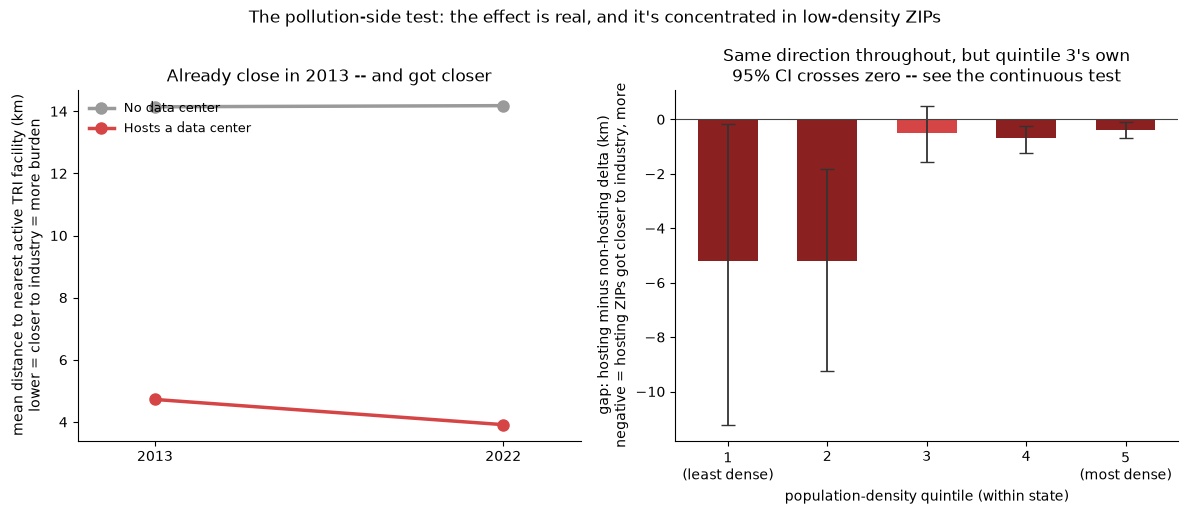

In [7]:
import matplotlib.pyplot as plt

BLUE, RED, GREY = "#2a78d6", "#d64545", "#9a9a9a"

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))

# Panel A: level trend, both years -- hosting ZIPs consistently much closer to active industry
ax = axes[0]
years = [2013, 2022]
ax.plot(years, [non["tri_dist_km_2013"].mean(), non["tri_dist_km_2022"].mean()],
        "o-", color=GREY, linewidth=2.5, markersize=8, label="No data center")
ax.plot(years, [host["tri_dist_km_2013"].mean(), host["tri_dist_km_2022"].mean()],
        "o-", color=RED, linewidth=2.5, markersize=8, label="Hosts a data center")
ax.set_xticks(years)
ax.set_xlim(2011, 2024)
ax.set_ylabel("mean distance to nearest active TRI facility (km)\nlower = closer to industry = more burden")
ax.set_title("Already close in 2013 -- and got closer")
ax.legend(loc="upper left", fontsize=9, frameon=False)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

# Panel B: gap per quintile (host - non) with bootstrap 95% CI -- shows the shakiness directly
# instead of a caption caveat, and the interaction regression (not this chart) carries the
# "is the pattern real" claim.
ax = axes[1]
x = np.arange(1, 6)
gap_err = np.array([tab["gap"] - tab["ci_lo"], tab["ci_hi"] - tab["gap"]])
colors = ["#d64545" if not excl else "#8b2020" for excl in tab["ci_excludes_zero"]]
ax.bar(x, tab["gap"], yerr=gap_err, capsize=5, color=colors, width=0.6,
       error_kw={"linewidth": 1.3, "ecolor": "#333333"})
ax.axhline(0, color="#444444", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(["1\n(least dense)", "2", "3", "4", "5\n(most dense)"])
ax.set_xlabel("population-density quintile (within state)")
ax.set_ylabel("gap: hosting minus non-hosting delta (km)\nnegative = hosting ZIPs got closer to industry, more")
ax.set_title("Same direction throughout, but quintile 3's own\n95% CI crosses zero -- see the continuous test")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

fig.suptitle("The pollution-side test: the effect is real, and it's concentrated in low-density ZIPs",
             fontsize=12.5)
fig.tight_layout()
fig.savefig("dc_ej_tri_impact_test.png", dpi=150, bbox_inches="tight")
plt.show()

## Source & caption notes

- **Question:** the demographic piece found the EJ gap is mostly selection. Does the
  pollution/hazard half tell the same story, or something different -- and can EPA data
  even go historical there? Checked feasibility first: Superfund/RCRA have no listing dates
  in the API fields the live pipeline uses; TRI does support a year filter through the same
  Envirofacts API `04_environment.py` already calls.
- **What TRI can and can't show:** data centers essentially never appear in TRI themselves
  (it's chemical manufacturing/processing, not IT/cooling). This tests whether the
  surrounding industrial neighborhood changed, not whether the data center itself polluted.
  Two live alternative explanations for any effect found: common-cause siting economics
  (land/power/zoning draw both DCs and new industry independently) and reverse causality
  (a rising industrial footprint could itself help attract data centers). Not resolved here.
- **Two real EPA data problems fixed, not glossed over:** `TRI_REPORTING_FORM`'s state
  filter is silently ignored (confirmed: two different states returned identical rows) --
  worked around with a national pull filtered by `REPORTING_YEAR` only, joined to a
  per-state `TRI_FACILITY` roster by ID. EPA's own facility geocoding is ~20-25% incomplete
  and, worse, unevenly so between years (73.8% of 2013's active reporters resolved vs. 61.3%
  of 2022's) -- left unfixed, this would have mechanically biased 2022 toward artificially
  farther distances just from a sparser candidate pool. Fixed with a ZIP-centroid fallback,
  closing the year-to-year gap from 12.5 points to 0.1 points.
- **Level finding (both years):** hosting ZIPs were already ~5x closer to an active TRI
  facility than non-hosting ZIPs in 2013 (median 1.83 km vs. 9.57 km) and remain so in 2022
  (1.23 km vs. 9.63 km) -- both real (p<1e-200, n~33k). Consistent with the demographic
  piece's selection story at the level.
- **Change finding:** hosting ZIPs' distance to the nearest active TRI facility shrank 0.81 km
  on average (got closer/worse) while non-hosting ZIPs were flat (+0.04 km). Controlling for
  density and each ZIP's 2013 starting point, hosting ZIPs still shrank 1.29 km more than
  matched non-hosting ZIPs -- real against a 200-shuffle permutation test (p=0.005).
- **Simon's direct follow-up, addressed properly rather than caveated away:** the quintile
  breakdown showed a much bigger gap in the two least-dense bins (n=38, 59 hosting ZIPs) --
  is that pattern real, or small-n noise? Two checks, not one. Bootstrap 95% CIs per quintile
  show only 4 of 5 individually clear zero (quintile 3's own CI crosses it, quintile 1's
  barely doesn't) -- the per-bar view alone is genuinely too noisy to lean on. A continuous
  `has_dc x density_axis` interaction regression (all 1,196 hosting ZIPs at once, no binning)
  settles it: the interaction term is real (t=4.70, permutation p=0.005) -- the effect
  genuinely shrinks with density, not an artifact of thin bins. Implied effect at low density
  (~10th percentile, rural): -2.12 km. At high density (~90th percentile, urban): +0.01 km,
  essentially zero. **The "industrial neighborhood intensifying" story belongs almost
  entirely to rural/exurban data-center ZIPs, not urban ones** -- a real refinement of the
  headline finding, not just a caveat on it.
- **Not proof of impact.** This residual (unlike the demographic piece's small ~10%-of-gap
  one) is real and substantial in rural ZIPs specifically -- but "the industrial neighborhood
  intensified faster near rural data-center ZIPs" is still consistent with common-cause
  siting economics (cheap land/power draws both) or reverse causality, not just a
  data-center-caused effect. Reported as the more impact-consistent of the two EPA tests run
  in this series, not as resolved.
- Image: `dc_ej_tri_impact_test.png` (2013\u21922022 level trend; per-quintile gap with
  bootstrap 95% CIs). Prep script: `data/build_tri_historical.py` (resumable, ~65 EPA API
  calls, cached under `data/tri_cache/`). Five hard asserts plus two permutation tests
  (has_dc coefficient, has_dc:density interaction) and a 2000-resample bootstrap.